## Pytorch_CNN_Patch

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import time
import pickle
import torch
import torch.nn as nn
import torch.optim as optim
import random
from torch.utils.data import * 
import datetime

In [2]:
if (torch.cuda.is_available()):
    device=torch.device("cuda")
    print('device is:',device)
else:
    device=torch.device("cpu")
    print('device is:',device)

device is: cpu


In [ ]:
torch.__version__

In [3]:
################################################################
model_name='biomeA'
################################################################

## Load Sentinel Patches

In [4]:
filename = '../Patch_data/' + model_name + '_patches.npy'
print(filename)
patch_images = np.load(filename)       
patch_images.shape

../Patch_data/biomeA_patches.npy


(20834, 10, 5, 5)

## Load GLanCE Labels

In [5]:
filename = '../Patch_data/' + model_name + '_patch_labels.npy'
print(filename)
patch_labels = np.load(filename)   
patch_labels.shape

../Patch_data/biomeA_patch_labels.npy


(20834,)

In [6]:
patch_label_names = ['Water(0)','Developed(1)','Barren(2)','Trees(3)','Shrub(4)','Grassland(5)','Agriculture(6)']
len(patch_label_names)

7

In [7]:
total=0
for i in range(7):
    count = np.sum(patch_labels == i) 
    total=total+count
    print(i,count)
print('total=',total)

0 3020
1 254
2 111
3 13443
4 394
5 2753
6 859
total= 20834


## Convert from Digital Number to Surface Reflectance

In [8]:
# normalise 0 -> 1 
patch_images_norm = patch_images.copy()

no_channels=10
for i in range(no_channels):                                                                # loop through all channels
    p99 = np.percentile(patch_images[:,i,:,:], 99)
    max = np.max(patch_images[:,i,:,:])
    print('channel =',i,' max =', max, ' p99 =', p99)
    #patch_images_norm[:,i,:,:] = (1.0/p99)*patch_images[:,i,:,:]                   # 0 to +1    max is p99 per band

patch_images_norm = patch_images/10000

patch_images_norm = np.minimum(patch_images_norm, 1.0)          # clip values above +1 stds
patch_images_norm = np.maximum(patch_images_norm, 0.0)          # clip values below 0 stds

channel = 0  max = 12520.0  p99 = 3592.0
channel = 1  max = 12640.0  p99 = 3573.0
channel = 2  max = 12760.0  p99 = 3480.5100000000093
channel = 3  max = 12976.0  p99 = 4830.255000000005
channel = 4  max = 12858.0  p99 = 3870.2550000000047
channel = 5  max = 12697.0  p99 = 4431.0
channel = 6  max = 12747.0  p99 = 4818.0
channel = 7  max = 12653.0  p99 = 5022.0
channel = 8  max = 8325.5  p99 = 4480.255000000005
channel = 9  max = 7000.0  p99 = 3596.0


In [9]:
print(patch_images_norm.min(), patch_images_norm.max())
print(patch_images_norm.mean(), patch_images_norm.std())

0.0 1.0
0.16644760238541806 0.10919783581893483


In [10]:
patch_images_norm.shape, patch_labels.shape

((20834, 10, 5, 5), (20834,))

## Create a Dataset Subclass - from Dataset Class

IDL page 26. Using common notation in ML, we need a set of input data X and associated output labels y. In PyTorch we represent that with a
`Dataset` object. By using this interface, PyTorch provides efficient loaders that automatically handle using multiple CPU cores to
pre-fetch the data and keep a limited amount of data in memory at a time.  
From `torch.utils.data import Dataset`. When an image is taken from the dataset it is converted to a pytorch tensor.


In [11]:
class Image_Dataset(Dataset):                # create a subclass of the Dataset class
        
    def __init__(self, X, y):                # X = input data, y is corresponding labels
        super().__init__()                   # Call the parent class's __init__ (not needed for Dataset but best practice)
        self.X = X
        self.y = y
         
    def __getitem__(self, index):            # get specific sample data and corresponding label & convert to tensor
        return torch.tensor(self.X[index], dtype=torch.float32), torch.tensor(self.y[index], dtype=torch.long)

    def __len__(self):
        return self.X.shape[0]


## Create a Dataset Object and Split into Training and Test Dataset

In [12]:
# GLanCE patch data
patch_ds_norm = Image_Dataset(patch_images_norm, patch_labels)    # create Image_Dataset object - normalised
patch_ds_raw = Image_Dataset(patch_images, patch_labels)          # create Image_Dataset object - raw data for plotting
train_size = int(len(patch_ds_norm)*0.8)                          # training size is 80%
test_size = len(patch_ds_norm) - train_size                       # test size is 20%
training_dataset, test_dataset = random_split(patch_ds_norm, (train_size, test_size))  # split the dataset into two; training and test
len(training_dataset), len(test_dataset), len(training_dataset) + len(test_dataset)

(16667, 4167, 20834)

## Plot single training image from patch_ds_norm dataset

In [ ]:
im_no=101         # select any image number

img1,lab1 = patch_ds_norm[im_no]

print('normalised data')
print("label",im_no," = ", patch_label_names[lab1.numpy()])   # GLanCE patch data

img1 = img1.numpy()            # from pytorch tensor to python numpy array
img2 = img1.transpose(1,2,0)   # C x H x W to H x W x C
                               # transpose for numpy, permute for tensor
img2 = img2[:,:,0:3]           # BGR ... there are four channels in total, only use first three
img2 = img2[:,:,::-1]          # RGB ... reverse the order of the last dimension

imin = img2.min()
imax = img2.max()
print('imin=',imin,'imax=',imax)

img2=img2*1.0
img2 = np.minimum(img2, 1.0)          # clip values above +1 
img2 = np.maximum(img2, 0.0)          # clip values below 0 

plt.imshow(img2)                      # normalised 0 to 1
plt.show()

## Plot single training image from patch_ds_raw dataset

In [ ]:
im_no=101         # select any image number

im1,lab1 = patch_ds_raw[im_no]

print('raw data')
print("label",im_no," = ", patch_label_names[lab1.numpy()])   # GLanCE patch data

im1 = im1.numpy()            # from pytorch tensor to python numpy array
im2 = im1.transpose(1,2,0)   # C x H x W to H x W x C
                             # transpose for numpy, permute for tensor
im2 = im2[:,:,0:3]           # BGR ... there are ten channels in total, only use first three
im2 = im2[:,:,::-1]          # RGB ... reverse the order of the last dimension

imin = im2.min()
imax = im2.max()
print('imin=',imin,'imax=',imax)

im3 = im2/10000
im3 = np.minimum(im3, 1.0)          # clip values above +1 
im3 = np.maximum(im3, 0.0)          # clip values below 0 

plt.imshow(im3)
plt.show()

## Define Model Class from nn.Module Class

In [13]:
# two conv layers and a fully connected layer and a softmax - Song plus FC layer
class Patch(nn.Module):
    def __init__(self):                                               # instantiate in the constructor
        super().__init__()                                            # in - m x 10 x 5 x 5
        self.conv1 = nn.Conv2d(10, 10, kernel_size=3, padding=0)      # out - m x 10 x 3 x 3
        self.act1 = nn.LeakyReLU()
        self.conv2 = nn.Conv2d(10, 20, kernel_size=2, padding=0)      # out - m x 20 x 2 x 2
        self.act2 = nn.LeakyReLU()
        # flatten
        self.fc1 = nn.Linear(80, 40)                                  # out - m x 40
        self.act3 = nn.LeakyReLU()
        self.fc2 = nn.Linear(40, 7)                                   # out logits - m x 7
                                                                      # common practice to output logits without activation function

    def forward(self, x):                            # uses the instances in forward
        out = self.act1(self.conv1(x))
        out = self.act2(self.conv2(out))
        out = out.view(-1, 80)                       # replacing nn.Flatten(), the size -1 is inferred from other dimensions
        out = self.act3(self.fc1(out))
        out = self.fc2(out)
        return out

## Instantiate the Model Object

In [14]:
# instantiate new model
model = Patch()    # Constructor - Patch is the class (subclass of nn.Module), model is the object

numel_list= [ p.numel() for p in model.parameters()]
sum(numel_list),numel_list

(5257, [900, 10, 800, 20, 3200, 40, 280, 7])

In [ ]:
print(model)

## Train the Model

In [15]:
#####################################################

epochs = 2000
batch_size = 64

####################################################

In [16]:
# Training Loader - from training dataset and batch size
training_loader = DataLoader(training_dataset, batch_size, shuffle=True, drop_last=True)
print('total samples =', len(training_dataset))
print('no of batches =', len(training_loader))

total samples = 16667
no of batches = 260


In [17]:
# Training Model
print(datetime.datetime.now())

start = time.time()

model = model.to(device)
optimizer = optim.SGD(model.parameters(), lr=0.01)                         # standard SGD. optimizer after moving model to device
loss_fn = nn.CrossEntropyLoss()                                            # Softmax + Negative Log Likelihood
                                                                           # model output shape is Batch x Classes
model.train()             # Put our model in training mode
    
average_loss=[]

no_batches = len(training_loader)
    
for epoch in range(1,epochs+1):

    running_loss = 0.0

    for images, labels in training_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)              # run model. inputs [B,C,H,W] outputs [batch_size, num_classes]
        loss = loss_fn(outputs, labels)      # calculate loss. labels [batch_size]. mean loss over all batch samples
                                             # NLLLoss delivers one loss per sample. The negative log likelihood
                                             # ...where likelihood is probability of the target class
        optimizer.zero_grad()                # set grads to zero
        loss.backward()                      # calculate gradients
        optimizer.step()                     # update paramers
            
        running_loss += loss.item()          # item() returns the value of this tensor as a standard Python number... 
                                             # this only works for tensors with one element.

    aloss = running_loss/no_batches
    average_loss.append(aloss)
    if (epoch % 1 == 0):
        print("CNN: %s. Epoch: %d, Loss: %f, epochs: %d x %d" % (model_name, epoch, aloss, epochs, batch_size))
                
end = time.time()
print('\n\nfinal run time=',(end-start)/60," minutes")

2026-03-26 14:10:37.397441
CNN: biomeA. Epoch: 1, Loss: 1.375417, epochs: 2000 x 64
CNN: biomeA. Epoch: 2, Loss: 1.083713, epochs: 2000 x 64
CNN: biomeA. Epoch: 3, Loss: 1.047684, epochs: 2000 x 64
CNN: biomeA. Epoch: 4, Loss: 1.001034, epochs: 2000 x 64
CNN: biomeA. Epoch: 5, Loss: 0.948244, epochs: 2000 x 64
CNN: biomeA. Epoch: 6, Loss: 0.906360, epochs: 2000 x 64
CNN: biomeA. Epoch: 7, Loss: 0.870501, epochs: 2000 x 64
CNN: biomeA. Epoch: 8, Loss: 0.835740, epochs: 2000 x 64
CNN: biomeA. Epoch: 9, Loss: 0.799027, epochs: 2000 x 64
CNN: biomeA. Epoch: 10, Loss: 0.760518, epochs: 2000 x 64
CNN: biomeA. Epoch: 11, Loss: 0.723507, epochs: 2000 x 64
CNN: biomeA. Epoch: 12, Loss: 0.692216, epochs: 2000 x 64
CNN: biomeA. Epoch: 13, Loss: 0.669853, epochs: 2000 x 64
CNN: biomeA. Epoch: 14, Loss: 0.653305, epochs: 2000 x 64
CNN: biomeA. Epoch: 15, Loss: 0.639643, epochs: 2000 x 64
CNN: biomeA. Epoch: 16, Loss: 0.628527, epochs: 2000 x 64
CNN: biomeA. Epoch: 17, Loss: 0.619801, epochs: 2000 x

In [ ]:
# which device is model on, cpu or gpu
print('model device=',next(model.parameters()).device)
print('outputs device=',outputs.device)

## Plot Loss

In [18]:
print(model_name)

biomeA


In [19]:
figure_name='../Patch_models/plot_loss_' + model_name + '.png'
figure_name

'../Patch_models/plot_loss_biomeA.png'

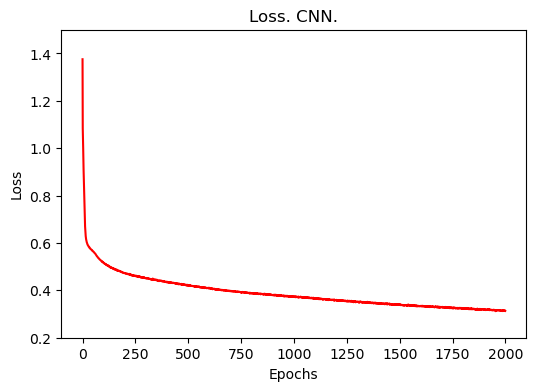

In [20]:
# plot average loss curve

plt.figure(figsize=(6, 4))  # width, height

plt.plot(average_loss,'red',label='loss') 
#plt.plot(aloss1,'blue',label='500x32') 

# Add titles and labels
plt.title('Loss. CNN.')
plt.xlabel('Epochs')
plt.ylabel('Loss')   
plt.ylim(0.2, 1.5)
#plt.legend()

plt.savefig(figure_name, dpi=600, bbox_inches="tight")

plt.show()

In [21]:
file_name='../Patch_models/loss_curve_' + model_name + '.npy'
file_name

'../Patch_models/loss_curve_biomeA.npy'

In [22]:
# save loss data as np array
np.save(file_name, np.array(average_loss))

In [ ]:
# load loss data 
load_loss = np.load("../Patch_models/loss_curve_BiomeB.npy")   
load_loss.shape

In [ ]:
total_loss = np.concatenate((load_loss,average_loss),axis=0)
total_loss.shape

In [ ]:
average_loss = total_loss
average_loss.shape

In [ ]:
# save total loss data as np array
np.save(file_name, np.array(total_loss))

## Test the Model

In [23]:
test_loader = DataLoader(test_dataset, batch_size=len(test_dataset), shuffle=False)   # a single batch

In [24]:
len(test_loader), test_loader.batch_size

(1, 4167)

In [25]:
model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        outputs = model(images)
        predicted_index = torch.argmax(outputs, dim=1)
        total = images.shape[0]
        correct = int((predicted_index == labels).sum())
        
print("Accuracy: %f" % (correct * 100 / total))
print("correct =",correct)
print("total =", total)

Accuracy: 85.769138
correct = 3574
total = 4167


In [ ]:
predicted_index.shape, labels.shape

## Confusion Matrix and F1 Score

In [26]:
figure_name='../Patch_models/plot_confusion_' + model_name + '.png'
figure_name

'../Patch_models/plot_confusion_biomeA.png'

In [27]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, f1_score

# Example data
y_true = labels
y_pred = predicted_index

f1_per_class = f1_score(y_true, y_pred, average=None)
f1_macro = f1_score(y_true, y_pred, average='macro')         # Averages F1 across all classes equally, no matter how big or small they are
f1_micro = f1_score(y_true, y_pred, average='micro')         # Equivalent to overall accuracy when each pixel has one label
f1_weighted = f1_score(y_true, y_pred, average='weighted')   # Dominant classes affect the result more
print('f1_macro =', f1_macro) 
print('f1_micro =', f1_micro) 
print('f1_weighted =', f1_weighted) 

f1_macro = 0.6187489472077384
f1_micro = 0.8576913846892249
f1_weighted = 0.8497711037249676


In [28]:
f1_per_class

array([0.96768982, 0.59259259, 0.53658537, 0.91492483, 0.13953488,
       0.62842012, 0.55149502])

In [29]:
cm = confusion_matrix(y_true, y_pred)

tp_per_class = np.diag(cm)
print(f"TP per class: {tp_per_class}") 

fp_per_class = cm.sum(axis=0) - np.diag(cm)
print(f"FP for each class: {fp_per_class}")

fn_per_class = cm.sum(axis=1) - np.diag(cm)
print(f"FN for each class: {fn_per_class}")

TP per class: [ 599   24   11 2495    6  356   83]
FP for each class: [ 29  11   5 284  11 208  45]
FN for each class: [ 11  22  14 180  63 213  90]


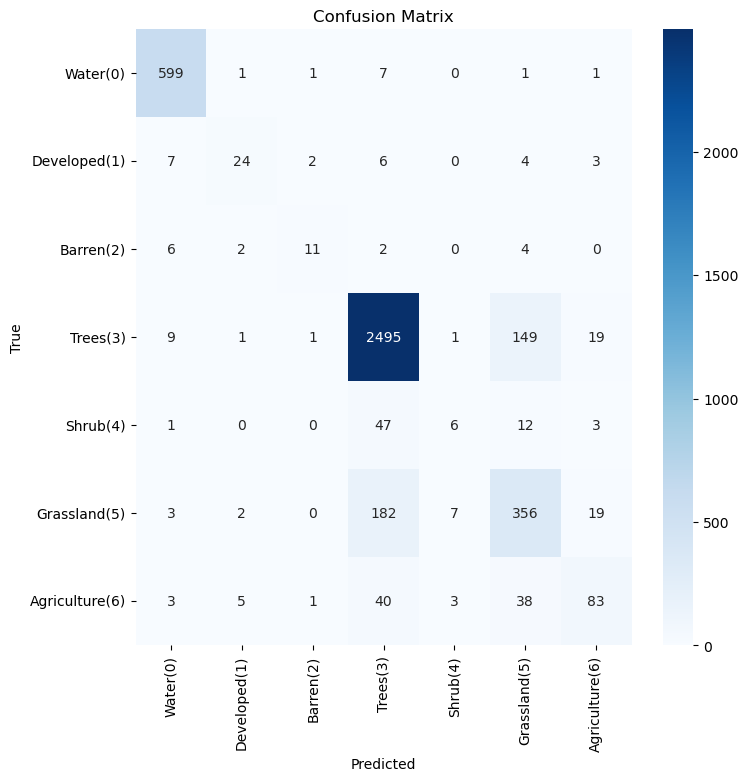

In [30]:
# Create the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot using Seaborn
plt.figure(figsize=(8, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=patch_label_names, yticklabels=patch_label_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig(figure_name, dpi=600, bbox_inches="tight")
plt.show()

## Test on Training Data (overfitting)

In [31]:
training_loader2 = DataLoader(training_dataset, batch_size=len(training_dataset), shuffle=False)  # a single batch

In [32]:
len(training_loader2), training_loader2.batch_size

(1, 16667)

In [33]:
model.eval()

with torch.no_grad():
    for images, labels in training_loader2:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predicted_index = torch.argmax(outputs, dim=1)
        total = images.shape[0]
        correct = int((predicted_index == labels).sum())
        
print("Accuracy: %f" % (correct * 100 / total))
print("correct =",correct)
print("total =", total)

Accuracy: 88.378232
correct = 14730
total = 16667


In [ ]:
size_in_bytes = patch_images_norm.nbytes
size_in_mb = size_in_bytes / (1024 ** 2)
print('size=',size_in_mb,'Mbytes')

## Save / Load Model to File  
**Deep Learning with Pytorch p214**

In [34]:
file_name='../Patch_models/Patch_' + model_name + '.pt'
file_name

'../Patch_models/Patch_biomeA.pt'

In [35]:
torch.save(model.state_dict(), file_name)

`johns_model.pt` now contains all the parameters of the model - weights and biases. No structure, just the weights.  
So when we deploy the model we need to keep the model class handy, create an instance, and then load the parameters back
into it.

In [ ]:
loaded_model = Patch()           # dont change the model class definition between saving and loading the model
loaded_model.load_state_dict(torch.load('../Patch_models/Patch_BiomeAll.pt', weights_only=True))

In [ ]:
print(loaded_model)

In [ ]:
model=loaded_model

## Training on the GPU - Deep Learning with Pytorch p215

Using the `.to` method we can move the tensors we get from the data loader to the GPU, after which our computation will
automatically take place there. But we also need to move our parameters to GPU. `nn.Module` implements a `.to` function which
moves all of its parameters to the GPU.

`Module.to` is in place; the Module instance is modified. But `Tensor.to` is out of place, returning a new tensor. One implication
is that its good practice to create the `Optimizer` after moving the parameters to the appropriate device. 
  
...basically. Move model to GPU and move input data and labels to GPU. When loading network weights PyTorch will attempt to load the weight to the same device it was saved from. You can instruct PyTorch to override the device information when loading weights by passing the `map_location` keyword.


In [ ]:
loaded_model = Net().to(device=device)
loaded_model.load_state_dict(torch.load('johns_model.pt',map_location=device))

## Sequential Models

### Sequential CNN with two Conv layers and two FC layers - BASIC CNN

In [ ]:
# Simple Sequential Model for CIFAR data
model = nn.Sequential(                                       # in (mb x 3 x 32 x 32)
            nn.Conv2d(3, 16, kernel_size=3, padding=1),      # out (mb x 16 x 32 x 32)
            nn.Tanh(),
            nn.MaxPool2d(2),                                 # out (mb x 16 x 16 x 16)
            nn.Conv2d(16, 8, kernel_size=3, padding=1),      # out (mb x 8 x 16 x 16)
            nn.Tanh(),
            nn.MaxPool2d(2),                                 # out (mb x 8 x 8 x 8)
            nn.Flatten(),                                    # out (mb x 512) -- 8x8x8=512
            nn.Linear(512, 128),                             # out (mb x 128)
            nn.LeakyReLU(),
            nn.Linear(128, 10))                              # out (mb x 10)

### Sequential CNN with two Conv layers two FC layers, and BatchNorm

In [ ]:
# Sequential Model with Batch Norm
model = nn.Sequential(                                                 # in (mb x 3 x 32 x32)
            nn.Conv2d(3, 16, kernel_size=3, padding=1,bias=False),     # out (mb x 16 x 32 x 32), bias=False for Batch Norm
            nn.BatchNorm2d(16),
            nn.Tanh(),
            nn.MaxPool2d(2),                                           # out (mb x 16 x 16 x 16)
            nn.Conv2d(16, 8, kernel_size=3, padding=1, bias=False),    # out (mb x 8 x 16 x 16), bias=False for Batch Norm
            nn.BatchNorm2d(8),
            nn.Tanh(),
            nn.MaxPool2d(2),                                           # out (mb x 8 x 8 x 8)
            nn.Flatten(),                                              # out (mb x 512) -- 8x8x8=512
            nn.Linear(512, 128),                                       # out (mb x 128)
            nn.LeakyReLU(),
            nn.Linear(128, 10))                                        # out (mb x 10)


### Sequential Model with two Conv layers, two FC layers and DropOut

In [ ]:
# sequential model with dropout regularisation
model = nn.Sequential(                                       # in (mb x 10 x 5 x 5)
            nn.Conv2d(10, 10, kernel_size=3, padding=1),     # out (mb x 10 x 5 x 5)
            nn.LeakyReLU(),
            nn.Dropout2d(p=0.1),                             # prob of dropout
            nn.Conv2d(10, 20, kernel_size=3, padding=1),     # out (mb x 20 x 5 x 5)
            nn.LeakyReLU(),
            nn.Dropout2d(p=0.1),                             # prob of dropout
            nn.Flatten(),                                    # out (mb x 500) -- 20x5x5=500
            nn.Linear(500, 250),                             # out (mb x 128)
            nn.LeakyReLU(),
            nn.Dropout(p=0.1),                               # prob of dropout
            nn.Linear(250, 6))                               # out (mb x 6)

### Sequential Model with two Conv layers, no Padding and 2x2 kernel for Conv2 - Song et al 2019

In [ ]:
# two conv layers only, without padding, 2x2 kernel for conv2 - Song et al 2019
model = nn.Sequential(                                          # in (mb x 10 x 5 x 5)
            nn.Conv2d(10, 10, kernel_size=3, padding=0),        # out (mb x 10 x 3 x 3)
            nn.LeakyReLU(),
            nn.Conv2d(10, 20, kernel_size=2, padding=0),        # out (mb x 20 x 2 x 2)
            nn.LeakyReLU(),
            nn.Flatten(),                                       # out (mb x 80)
            nn.Linear(80, 7))                                   # out (mb x 7)

## Other Models using nn.Module class

### Two Fully Connected Layers and a Softmax

In [ ]:
# two fully connected layers and a softmax
class Pure_FC(nn.Module):
    def __init__(self):                                               # instantiate in the constructor
        super().__init__()                                            # in - m x 10 x 5 x 5 -> flattern -> m x 250
        self.fc1 = nn.Linear(250, 125)                                # out - m x 125
        self.act1 = nn.LeakyReLU()                                    #
        self.fc2 = nn.Linear(125, 60)                                 # out - m x 60
        self.act2 = nn.LeakyReLU()                                    #
        self.fc3 = nn.Linear(60,7)                                    # out - m x 7

    def forward(self, x):                             
        out = x.view(-1, 250)                                         # flatten all patches to start
        out = self.act1(self.fc1(out))
        out = self.act2(self.fc2(out))
        out = self.fc3(out)       
        return out

### Two Fully Connected Layers and a Softmax ... with Dropout

In [ ]:
# two fully connected layers and a softmax ... with dropout
class Pure_FC_dropout(nn.Module):
    def __init__(self):                                               # instantiate in the constructor
        super().__init__()                                            # in - m x 10 x 5 x 5 -> flattern -> m x 250
        self.fc1 = nn.Linear(250, 125)                                # out - m x 125
        self.act1 = nn.LeakyReLU()                                    #
        self.fc1_dropout = nn.Dropout(p=0.2)                          # probablity inputs are zeroed out
        self.fc2 = nn.Linear(125, 60)                                 # out - m x 60
        self.act2 = nn.LeakyReLU()                                    #
        self.fc2_dropout = nn.Dropout(p=0.2)                          # probablity inputs are zeroed out
        self.fc3 = nn.Linear(60,7)                                    # out - m x 7

    def forward(self, x):                             
        out = x.view(-1, 250)                                         # flatten all patches to start
        out = self.act1(self.fc1(out))
        out = self.fc1_dropout(out)                                   # dropout from fc1
        out = self.act2(self.fc2(out))
        out = self.fc2_dropout(out)                                   # dropout from fc2
        out = self.fc3(out)       
        return out